# Baldick's SOC-Based Market vs. the "Current" Interval-Bidding Market

Two market designs, cleared **sequentially**, on the same physical system.

1. **Baldick's design** (`markets.day_ahead.solve_day_ahead`, as in
   [`reproduce_baldick.ipynb`](reproduce_baldick.ipynb)): the ISO optimizes the storage's
   whole SOC trajectory jointly, over the entire horizon, from a single end-of-horizon
   bid. No interval-by-interval offer from the storage owner at all.
2. **The "current" design** (this notebook's new
   [`../experiments/current_market.py`](../experiments/current_market.py)): storage
   participates the way most ISOs handle it today (Section 3 of the paper) -- a paired
   generator/load submitting an offer/bid *each interval separately*. The reference price
   it bids against is `pi_t`, the exact SOC costate stage 1's own clearing computed for
   this same system -- an oracle no real self-scheduling owner would actually have.

The point isn't to see which is "cheaper" in some naive sense -- it's to see what
clearing each interval **independently**, with no SOC bookkeeping in the market itself,
actually does to the physical storage trajectory, even when the reference price used is
about as good as it could possibly be.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from experiments.current_market import solve_sequential
from experiments.reproduce_baldick import CASES, run_case

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4)

## How the "current" model decides charge vs. discharge

`experiments/current_market.py` clears each interval as its own small economic dispatch:
storage offers to **discharge** at `pi_t + zeta` (a normal generator offer -- dispatched
whenever the clearing price is at or above it) and bids to **charge** at `pi_t - epsilon`
(a normal elastic-demand bid -- consumes whenever the price is at or below it). Nothing
hand-codes "if price > pi_t, discharge" -- that rule falls straight out of a standard
cost-minimizing LP once storage is modeled as an ordinary paired generator/load, exactly
the way Section 3 of the paper describes current practice.

Degradation (`epsilon`/`zeta`) is included for a concrete reason, not just realism:
without it, whenever the clearing price lands exactly on `pi_t` (which happens often,
since storage's own bid/offer is frequently what sets that price), charging and
discharging at once nets to the same cost as doing neither, and the LP is free to pick
an arbitrarily large, physically senseless simultaneous charge-and-discharge. A strictly
positive cost per MWh moved rules that out.

Each interval is solved **on its own** -- nothing links interval `t` to interval `t+1`.
That absence is the entire model, not a simplification: it is exactly what "storage bids
like a generator and a load, hour by hour" means, and it is exactly what Baldick's own
design replaces with a single end-of-horizon bid the ISO manages centrally.

## Case 1: `base_case`

Baldick's own base case -- $w=\$40$/MWh, flat, below the thermal offer price -- already
extensively documented in `reproduce_baldick.ipynb`. Stage 1 solves it first; `pi_t`
(the SOC costate) becomes the sequential model's reference price for every interval.

In [2]:
name = "base_case"
system, _ = CASES[name]
baldick = run_case(name)
storage = system.storages[0]
pi = baldick.pi[0]

seq = solve_sequential(system, storage, pi)

print("pi_t (Baldick's SOC costate, used as the sequential model's reference price):")
print(pi.round(3))

pi_t (Baldick's SOC costate, used as the sequential model's reference price):
[49.     1.111  1.111  1.111 49.    40.   ]


### Dispatch, side by side

In [3]:
print("Stage 1 -- Baldick's own SOC-based clearing:")
display(baldick.to_frame())

print("\nStage 2 -- the 'current', interval-by-interval clearing:")
display(seq.to_frame())

Stage 1 -- Baldick's own SOC-based clearing:


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,322.222,0.000,0.000,22.222,800.000,0.000
5,25.000,0.000,175.000,0.000,100.000,50.000
6,0.000,75.000,25.000,0.000,0.000,50.000



Stage 2 -- the 'current', interval-by-interval clearing:


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),SOC within limits,Price ($/MWh)
Interval,,,,,,,
1,200.000,0.000,0.000,100.000,360.000,True,48.000
2,100.000,0.000,100.000,0.000,-40.000,False,2.111
3,500.000,0.000,0.000,200.000,680.000,True,0.000
4,500.000,0.000,0.000,200.000,"1,400.000",False,0.000
5,25.000,100.000,75.000,0.000,"1,100.000",False,50.000
6,0.000,0.000,100.000,0.000,700.000,True,41.000


Baldick's own SOC column is the *optimal* trajectory -- chosen jointly, respecting
`[s_min, s_max]` by construction. The sequential model's SOC column is not a decision at
all; it is what charging and discharging by the price-vs-`pi_t` rule, interval after
interval with no memory of the running total, *would leave behind* -- and the "SOC within
limits" column shows exactly where that stops being physically possible.

### SOC trajectories: optimal vs. merely derived

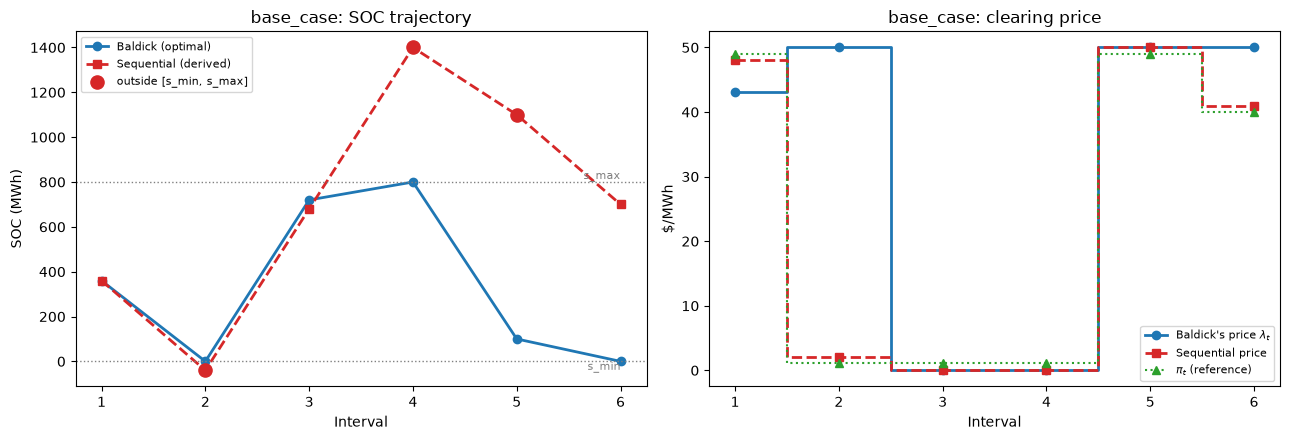

In [4]:
fig, (ax_soc, ax_price) = plt.subplots(1, 2, figsize=(13, 4.5))
hours = range(1, system.T + 1)

ax_soc.plot(hours, baldick.soc[0], marker="o", color="#1F77B4", linewidth=2, label="Baldick (optimal)")
ax_soc.plot(hours, seq.soc, marker="s", color="#D62728", linewidth=2, linestyle="--", label="Sequential (derived)")
ax_soc.axhline(storage.s_max, color="grey", linewidth=1, linestyle=":")
ax_soc.axhline(storage.s_min, color="grey", linewidth=1, linestyle=":")
ax_soc.text(system.T, storage.s_max, " s_max", va="bottom", ha="right", color="grey", fontsize=8)
ax_soc.text(system.T, storage.s_min, " s_min", va="top", ha="right", color="grey", fontsize=8)
infeasible = ~seq.soc_within_bounds
if infeasible.any():
    ax_soc.scatter(np.array(list(hours))[infeasible], seq.soc[infeasible], color="#D62728", s=90, zorder=5, label="outside [s_min, s_max]")
ax_soc.set_title(f"{name}: SOC trajectory")
ax_soc.set_xlabel("Interval")
ax_soc.set_ylabel("SOC (MWh)")
ax_soc.legend(fontsize=8)

ax_price.step(hours, baldick.price, where="mid", marker="o", color="#1F77B4", linewidth=2, label="Baldick's price $\\lambda_t$")
ax_price.step(hours, seq.price, where="mid", marker="s", color="#D62728", linewidth=2, linestyle="--", label="Sequential price")
ax_price.step(hours, pi, where="mid", marker="^", color="#2CA02C", linewidth=1.5, linestyle=":", label="$\\pi_t$ (reference)")
ax_price.set_title(f"{name}: clearing price")
ax_price.set_xlabel("Interval")
ax_price.set_ylabel("$/MWh")
ax_price.legend(fontsize=8)

fig.tight_layout()
plt.show()

### Real cost comparison

Evaluated at *actual* system costs (generation + degradation) in both cases -- not the
`pi_t` bid/offer terms the sequential model's own clearing uses internally, which are a
dispatch *mechanism*, not a real cost, exactly as `threshold_bid.py`'s "true valuation"
distinction works.

**This comparison needs a caveat, not just a number.** Whenever the sequential
model's derived SOC lands outside `[s_min, s_max]`, its dispatch is not something the
physical battery could actually have delivered -- so a *lower* real cost there does not
mean the current design is more efficient; it means the comparison is with an
infeasible trajectory. Read the cost gap alongside the feasibility column, not instead
of it.

In [5]:
print(f"Baldick's real cost ($):          {baldick.objective:,.2f}")
print(f"Sequential model's real cost ($):  {seq.true_cost(system, storage):,.2f}")
print(f"Intervals with SOC outside [s_min, s_max]: {(~seq.soc_within_bounds).sum()} of {system.T}")

Baldick's real cost ($):          19,448.89
Sequential model's real cost ($):  23,100.00
Intervals with SOC outside [s_min, s_max]: 3 of 6


## Case 2: `high_willingness_to_pay`

Same exercise, `w=\$55$/MWh -- above the thermal offer price, so Baldick's own design
holds 500 MWh in reserve at the end of the horizon (Table 3). Repeated to check the
pattern isn't an artifact of one particular `pi_t` shape.

In [6]:
name = "high_willingness_to_pay"
system, _ = CASES[name]
baldick = run_case(name)
storage = system.storages[0]
pi = baldick.pi[0]

seq = solve_sequential(system, storage, pi)

print("Stage 1 -- Baldick's own SOC-based clearing:")
display(baldick.to_frame())

print("\nStage 2 -- the 'current', interval-by-interval clearing:")
display(seq.to_frame())

Stage 1 -- Baldick's own SOC-based clearing:


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,322.222,0.000,0.000,22.222,800.000,0.000
5,25.000,100.000,75.000,0.000,500.000,56.000
6,0.000,100.000,0.000,0.000,500.000,56.000



Stage 2 -- the 'current', interval-by-interval clearing:


,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),SOC within limits,Price ($/MWh)
Interval,,,,,,,
1,200.000,0.000,0.000,100.000,360.000,True,48.000
2,100.000,0.000,100.000,0.000,-40.000,False,2.111
3,500.000,0.000,0.000,200.000,680.000,True,0.000
4,500.000,0.000,0.000,200.000,"1,400.000",False,0.000
5,25.000,100.000,75.000,0.000,"1,100.000",False,56.000
6,0.000,100.000,0.000,0.000,"1,100.000",False,54.000


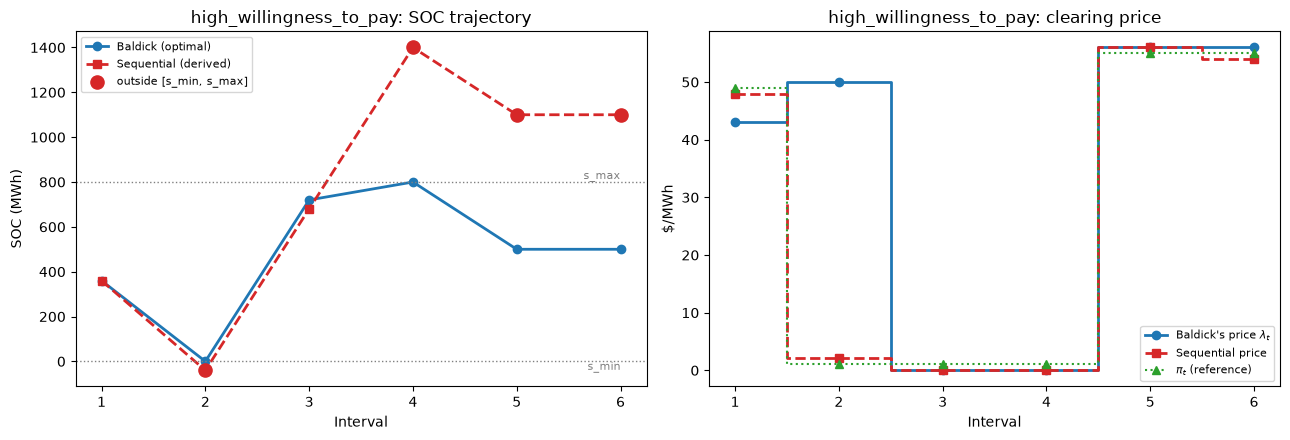

Baldick's real cost ($):          16,448.89
Sequential model's real cost ($):  42,700.00
Intervals with SOC outside [s_min, s_max]: 4 of 6


In [7]:
fig, (ax_soc, ax_price) = plt.subplots(1, 2, figsize=(13, 4.5))
hours = range(1, system.T + 1)

ax_soc.plot(hours, baldick.soc[0], marker="o", color="#1F77B4", linewidth=2, label="Baldick (optimal)")
ax_soc.plot(hours, seq.soc, marker="s", color="#D62728", linewidth=2, linestyle="--", label="Sequential (derived)")
ax_soc.axhline(storage.s_max, color="grey", linewidth=1, linestyle=":")
ax_soc.axhline(storage.s_min, color="grey", linewidth=1, linestyle=":")
ax_soc.text(system.T, storage.s_max, " s_max", va="bottom", ha="right", color="grey", fontsize=8)
ax_soc.text(system.T, storage.s_min, " s_min", va="top", ha="right", color="grey", fontsize=8)
infeasible = ~seq.soc_within_bounds
if infeasible.any():
    ax_soc.scatter(np.array(list(hours))[infeasible], seq.soc[infeasible], color="#D62728", s=90, zorder=5, label="outside [s_min, s_max]")
ax_soc.set_title(f"{name}: SOC trajectory")
ax_soc.set_xlabel("Interval")
ax_soc.set_ylabel("SOC (MWh)")
ax_soc.legend(fontsize=8)

ax_price.step(hours, baldick.price, where="mid", marker="o", color="#1F77B4", linewidth=2, label="Baldick's price $\\lambda_t$")
ax_price.step(hours, seq.price, where="mid", marker="s", color="#D62728", linewidth=2, linestyle="--", label="Sequential price")
ax_price.step(hours, pi, where="mid", marker="^", color="#2CA02C", linewidth=1.5, linestyle=":", label="$\\pi_t$ (reference)")
ax_price.set_title(f"{name}: clearing price")
ax_price.set_xlabel("Interval")
ax_price.set_ylabel("$/MWh")
ax_price.legend(fontsize=8)

fig.tight_layout()
plt.show()

print(f"Baldick's real cost ($):          {baldick.objective:,.2f}")
print(f"Sequential model's real cost ($):  {seq.true_cost(system, storage):,.2f}")
print(f"Intervals with SOC outside [s_min, s_max]: {(~seq.soc_within_bounds).sum()} of {system.T}")

## Why this happens, in one line

`pi_t` only prices *stored energy*, not the *running level* of it. A generator offered
at `pi_t` will sell its whole capacity every single interval the price clears above that
number, with no idea whether the tank is already empty; a load bid at `pi_t` will buy its
whole capacity every interval the price clears below it, with no idea whether the tank is
already full. Baldick's own design prices exactly the same `pi_t` -- Eqs. K4-K5's
backward recursion is where it comes from -- but the ISO uses it to choose a *trajectory*
under `[s_min, s_max]`, not to clear disconnected one-shot auctions. Same shadow price,
completely different amount of information reaching the dispatch decision.

## A note on `power_limit`

`solve_sequential` defaults each interval's discharge/charge cap to `s_max/dt` -- enough
to move from empty to full within a single interval -- since Baldick's own storages
carry no explicit power rating (`p_max`/`g_max` default to infinite, which is fine for a
*jointly*-optimized horizon but leaves the interval-by-interval market unbounded without
one). That default is large enough, relative to this system's demand, that storage often
ends up setting the interval's price itself rather than thermal or renewable doing so
(watch how often the green $\\pi_t$ line and the red sequential-price line coincide
above). A smaller, more realistically-rated `power_limit` is worth trying as a
follow-up -- pass it explicitly to `solve_sequential(system, storage, pi, power_limit=...)`.